# Exploring the Data

Ideas:
* Names:
    - Seeing consistent clients throughout time (monthly)
    - Summing over hourly and seeing change of demand per hour
* Postal code:
    - Distribution of zipcodes
    - Change in clusters throughout time (monthly/hourly)
* Numbers:
    - Change number of seniors/adults/youth/babies supported throughout time (monthly)
    - Sum of all numbers
        * Seeing that change over time as well
* Household:
    - Comparing if sum of numbers == household size
* Gender:
    - Distribution (in general and temporal- monthly/hourly)
* Overall:
    - Predicting demand (Regression - Pytorch)
    - Client clusters (KMeans)



In [46]:
##### Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

DATA_PATH = os.path.join(
    os.getcwd(),
    'Data'
)

df = pd.read_csv(
    f'{DATA_PATH}/food_clean.csv',
    parse_dates=['conversion_date']
)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 912 entries, 0 to 911
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   first_name         912 non-null    str           
 1   last_name          912 non-null    str           
 2   postal_code        912 non-null    int64         
 3   number_of_seniors  912 non-null    int64         
 4   number_of_adults   912 non-null    int64         
 5   number_of_youth    912 non-null    int64         
 6   number_of_babies   912 non-null    int64         
 7   household_size     912 non-null    float64       
 8   gender             912 non-null    str           
 9   conversion_date    912 non-null    datetime64[us]
dtypes: datetime64[us](1), float64(1), int64(5), str(3)
memory usage: 71.4 KB


In [47]:
##### Creating month and hourly variables
df['month'] = df['conversion_date'].dt.month
df['hour'] = df['conversion_date'].dt.hour

##### Summing up individual numbers of populations
population_cols = [col for col in df.columns if col.startswith('number')]
df['number_household_sum'] = df[population_cols[0]] + \
    df[population_cols[1]] + \
    df[population_cols[2]] + \
    df[population_cols[3]]

##### Quantitative and Qualitative Variables
quant_vars = [col for col in df.columns if col.startswith('number')]
qual_vars = list(set(df.columns) - set(quant_vars))


,number_of_seniors,number_of_adults,number_of_youth,number_of_babies,number_household_sum
count,912.000000,912.000000,912.000000,912.000000,912.000000
mean,1.130482,2.086623,1.282895,0.570175,5.070175
std,1.373048,1.342605,1.374463,1.089572,3.516233
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,0.000000,0.000000,2.000000
50%,1.000000,2.000000,1.000000,0.000000,4.000000
75%,2.000000,3.000000,2.000000,1.000000,7.000000
max,5.000000,5.000000,5.000000,5.000000,20.000000


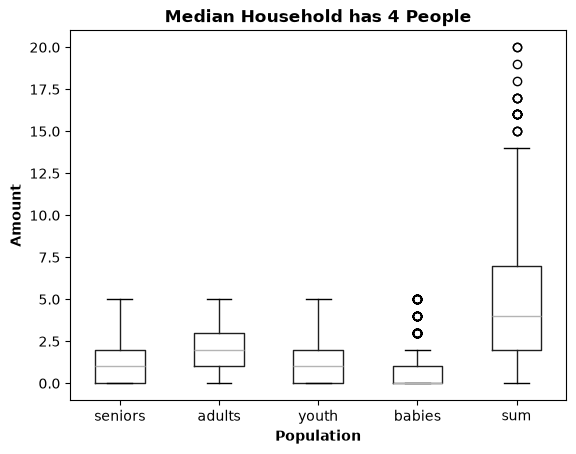

In [ ]:
##### General distributions - Quant variables
### Normalizing quant_vars
# df_quant_norm = (
#     df[quant_vars] - df[quant_vars].mean()
# )/df[quant_vars].std(ddof=0)

### Statistics
display(df[quant_vars].describe())
### Box and Whisker
boxplot = df.boxplot(
    column=quant_vars, 
    grid=False,
)
## X Axis
boxplot.set_xticklabels(
    [col.split("_")[-1] for col in quant_vars]
)
boxplot.set_xlabel("Population", fontweight='bold')
## Y Axis
boxplot.set_ylabel("Num of Members", fontweight='bold')
## Title
boxplot.set_title('Median Household has 4 People', fontweight='bold')
plt.show()

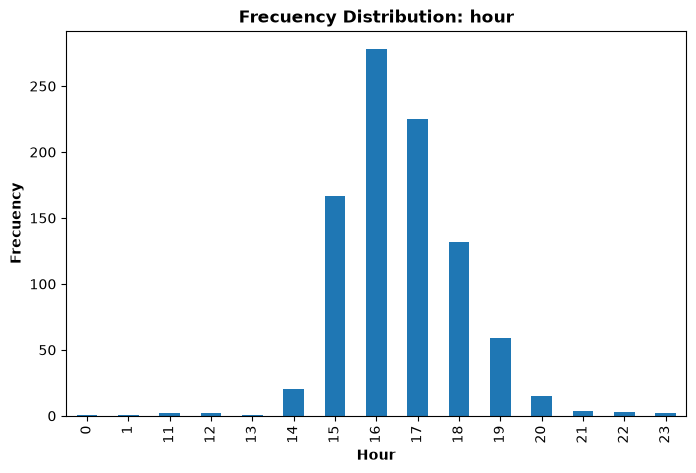

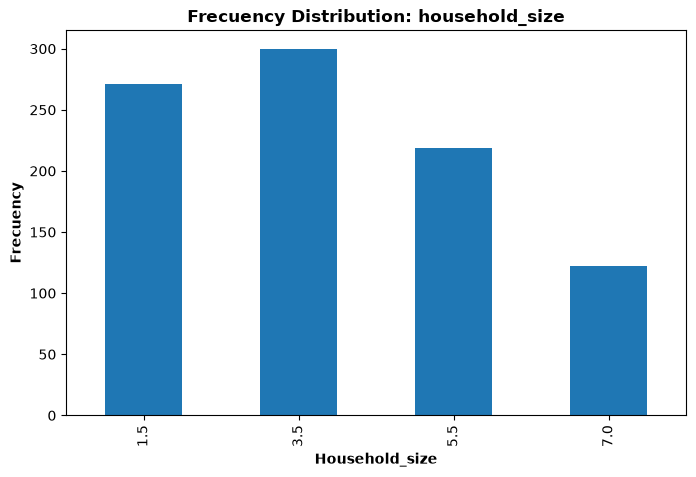

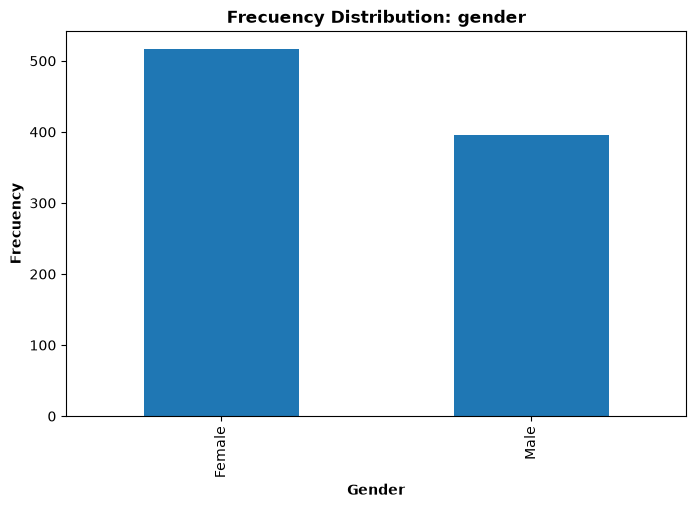

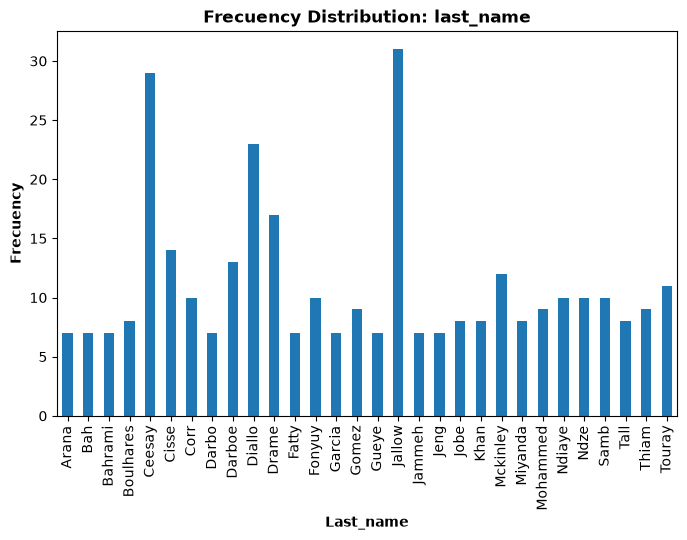

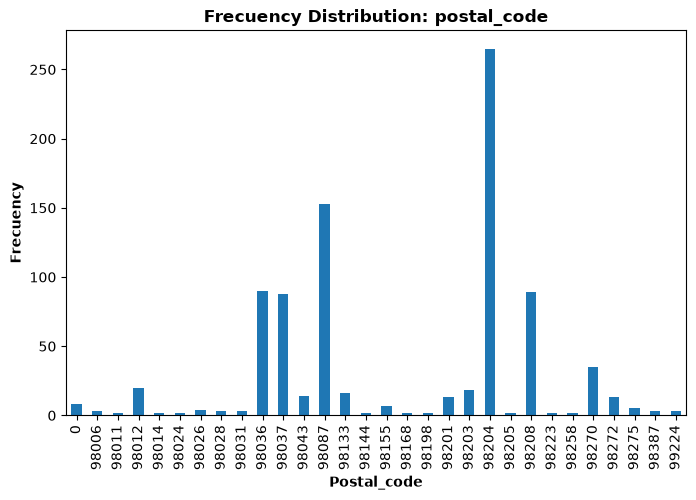

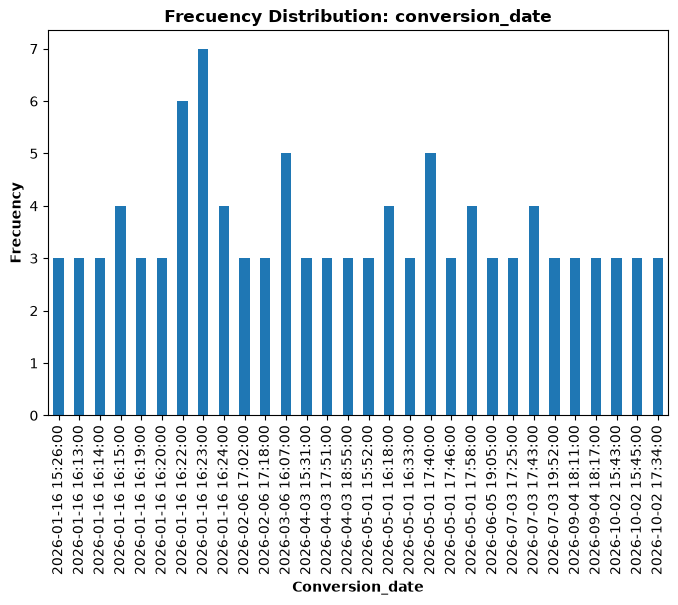

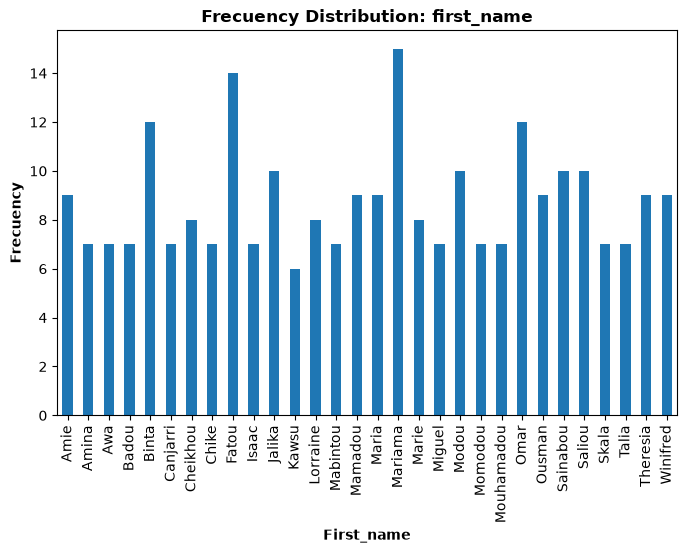

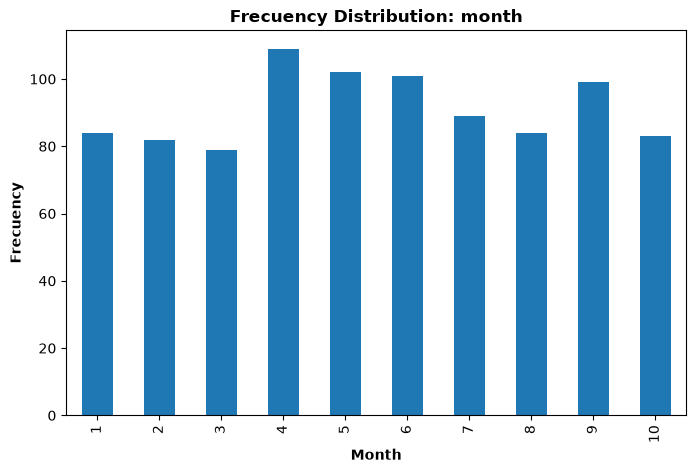

In [54]:
##### Distribution - qual_vars
for col in qual_vars:
    qual_nums = df[col].value_counts()[:30]
    qual_nums = qual_nums.sort_index()
    # print(qual_nums)
    ax = qual_nums.plot.bar(
        figsize=(8,5)
    )
    ax.set_xlabel(col.capitalize(), fontweight='bold')
    ax.set_ylabel('Frecuency', fontweight='bold')
    ax.set_title(
        f'Frecuency Distribution: {col}',
        fontweight='bold'
    )
    plt.show()

In [55]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 912 entries, 0 to 911
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   first_name            912 non-null    str           
 1   last_name             912 non-null    str           
 2   postal_code           912 non-null    int64         
 3   number_of_seniors     912 non-null    int64         
 4   number_of_adults      912 non-null    int64         
 5   number_of_youth       912 non-null    int64         
 6   number_of_babies      912 non-null    int64         
 7   household_size        912 non-null    float64       
 8   gender                912 non-null    str           
 9   conversion_date       912 non-null    datetime64[us]
 10  month                 912 non-null    int32         
 11  hour                  912 non-null    int32         
 12  number_household_sum  912 non-null    int64         
dtypes: datetime64[us](1), float64(1

,month,hour,num_clients
5,1,14,0
0,1,15,11
1,1,16,56
2,1,17,5
3,1,18,2
...,...,...,...
84,10,18,4
85,10,19,1
87,10,20,0
89,10,21,0


C:\Users\JP\AppData\Local\Temp\ipykernel_52960\3633004615.py:106: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(all_hours)


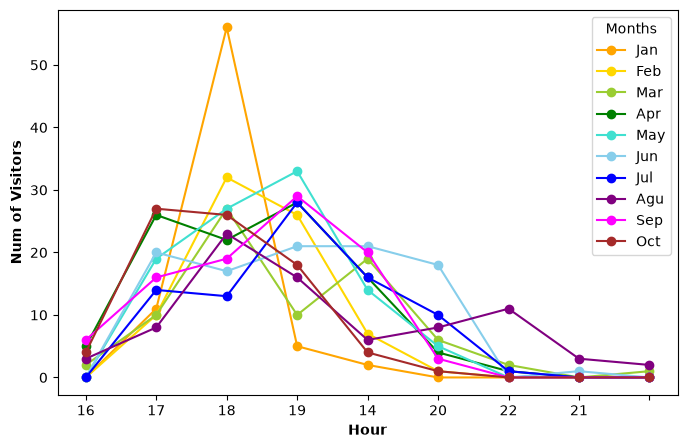

In [ ]:
##### First Name
# * Names:
#     - Seeing consistent clients throughout time (monthly)
#     - Summing over hourly and seeing change of demand per hour

#### Consistent clients
df_consistent_clients = df.groupby(
    by=['first_name','last_name'],
    as_index=False
).agg(
    num_months_visited = pd.NamedAgg(
        column='month',
        aggfunc=lambda series: series.nunique()
    ),
    household_sum = pd.NamedAgg(
        column='number_household_sum',
        aggfunc=lambda series: series.mean().round(2)
    )
).sort_values(
    by='num_months_visited',
    # by='household_sum',
    ascending=False
)

# display(df_consistent_clients)





#### Change of demand per hour
df_monthly_hour_change = df.groupby(
    by=['month','hour'],
    as_index=False
).agg(
    num_clients = pd.NamedAgg(
        column='first_name',
        aggfunc= lambda series: series.nunique()
    )
).sort_values(
    by=['month','hour'],
    ascending=[True,True]
)

#### Dropping outliers
    # Registrations at the following hours occured 1/2 times:
        # 0,1,11,12,13,23
df_monthly_hour_change = df_monthly_hour_change[
    ~df_monthly_hour_change['hour'].isin([0,1,11,12,13,23])
]

#### Ensuring all months have the same hours
all_months =df_monthly_hour_change['month'].unique()
all_hours = df_monthly_hour_change['hour'].unique()
full_index = pd.MultiIndex.from_product(
    [all_months, all_hours],
    names=['month','hour']
)
df_complete_m_h_change = df_monthly_hour_change\
    .set_index(['month', 'hour'])\
    .reindex(full_index, fill_value=0)\
    .reset_index()\
    .sort_values(
        by=['month','hour'],
        ascending=[True,True]
    )

display(df_complete_m_h_change)

#### Visualization
ANCH = 8
ALT = 5
fig, ax = plt.subplots(figsize=(ANCH,ALT))
num_unique_hours = np.arange(len(all_hours))
num_unique_months = np.arange(len(all_months)) + 1
months=[
    'Jan', 'Feb', 'Mar', 'Apr', 'May',
    'Jun', 'Jul', 'Agu', 'Sep', 'Oct'
]
colors = [
    "red",          # Enero
    "orange",       # Febrero
    "gold",         # Marzo
    "yellowgreen",  # Abril
    "green",        # Mayo
    "turquoise",    # Junio
    "skyblue",      # Julio
    "blue",         # Agosto
    "purple",       # Septiembre
    "magenta",      # Octubre
    "brown",        # Noviembre
    "gray"          # Diciembre
]
for month_num in num_unique_months:
    ax.plot(
        num_unique_hours,
        df_complete_m_h_change[
            df_complete_m_h_change['month'] == month_num
        ]['num_clients'],
        label = months[month_num-1],
        color= colors[month_num],
        marker='o',
    )
### Configs
ax.set_ylabel('Num of Visitors', fontweight='bold')
ax.set_xticklabels(all_hours)
ax.set_xlabel('Hour', fontweight='bold')
ax.legend(
    title='Month'
)
plt.show()

